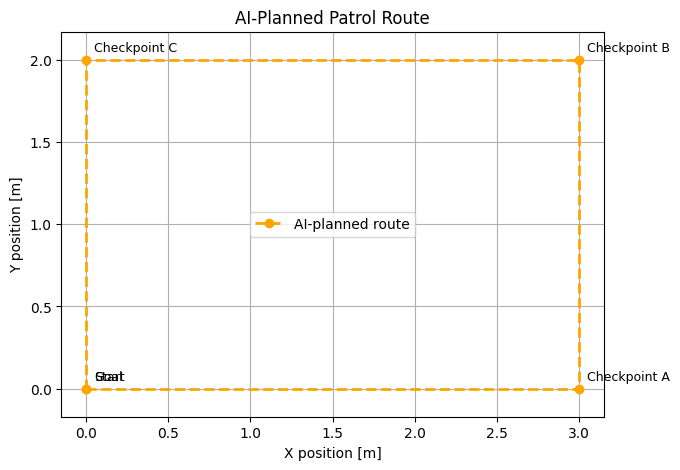

Route data was saved to waypoints.json
{
  "task": "地域施設内の見守り巡回",
  "generated_by": "Generative AI",
  "coordinate_unit": "meter",
  "waypoints": [
    {
      "name": "Start",
      "x": 0.0,
      "y": 0.0
    },
    {
      "name": "Checkpoint A",
      "x": 3.0,
      "y": 0.0
    },
    {
      "name": "Checkpoint B",
      "x": 3.0,
      "y": 2.0
    },
    {
      "name": "Checkpoint C",
      "x": 0.0,
      "y": 2.0
    },
    {
      "name": "Goal",
      "x": 0.0,
      "y": 0.0
    }
  ]
}


In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt

# 生成AIに「施設内を巡回する差動二輪ロボットの経路を
# 座標形式で作成してください」と依頼して得た経路データ
route_data = {
    "task": "地域施設内の見守り巡回",
    "generated_by": "Generative AI",
    "coordinate_unit": "meter",
    "waypoints": [
        {"name": "Start", "x": 0.0, "y": 0.0},
        {"name": "Checkpoint A", "x": 3.0, "y": 0.0},
        {"name": "Checkpoint B", "x": 3.0, "y": 2.0},
        {"name": "Checkpoint C", "x": 0.0, "y": 2.0},
        {"name": "Goal", "x": 0.0, "y": 0.0}
    ]
}

# AI生成経路をJSONファイルとして保存
with open("waypoints.json", "w", encoding="utf-8") as f:
    json.dump(route_data, f, ensure_ascii=False, indent=2)

# 経路を読み込み
with open("waypoints.json", "r", encoding="utf-8") as f:
    loaded_route = json.load(f)

x = [point["x"] for point in loaded_route["waypoints"]]
y = [point["y"] for point in loaded_route["waypoints"]]

# AIが生成した目標経路を表示
plt.figure(figsize=(7, 5))
plt.plot(x, y, "o--", color="orange", linewidth=2, label="AI-planned route")

for point in loaded_route["waypoints"]:
    plt.text(
        point["x"] + 0.05,
        point["y"] + 0.05,
        point["name"],
        fontsize=9
    )

plt.title("AI-Planned Patrol Route")
plt.xlabel("X position [m]")
plt.ylabel("Y position [m]")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

print("Route data was saved to waypoints.json")
print(json.dumps(loaded_route, ensure_ascii=False, indent=2))

In [3]:
import json
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Video, display

# 生成AIが作成した経路データを読み込む
with open("waypoints.json", "r", encoding="utf-8") as f:
    route_data = json.load(f)

waypoints = route_data["waypoints"]

# 差動二輪ロボットの初期状態
x = waypoints[0]["x"]
y = waypoints[0]["y"]
theta = 0.0

dt = 0.05          # シミュレーション周期
max_speed = 0.6    # 最大並進速度
max_turn = 2.0     # 最大旋回速度
goal_tolerance = 0.05

history = [(x, y, theta)]
reached_points = [0]

# 各チェックポイントへ順番に移動
for target_index, target in enumerate(waypoints[1:], start=1):

    for step in range(2000):
        dx = target["x"] - x
        dy = target["y"] - y
        distance = math.hypot(dx, dy)

        if distance < goal_tolerance:
            reached_points.append(len(history) - 1)
            break

        target_angle = math.atan2(dy, dx)

        # 角度を -π ～ π に収める
        angle_error = math.atan2(
            math.sin(target_angle - theta),
            math.cos(target_angle - theta)
        )

        # P制御：目標方向へ旋回しながら前進
        angular_velocity = np.clip(
            3.0 * angle_error,
            -max_turn,
            max_turn
        )

        linear_velocity = min(max_speed, distance)

        # 目標方向を向いていないときは前進速度を落とす
        linear_velocity *= max(0.0, math.cos(angle_error))

        # ロボットの状態を更新
        x += linear_velocity * math.cos(theta) * dt
        y += linear_velocity * math.sin(theta) * dt
        theta += angular_velocity * dt

        history.append((x, y, theta))

history = np.array(history)

# アニメーション作成
fig, ax = plt.subplots(figsize=(7, 6))

route_x = [p["x"] for p in waypoints]
route_y = [p["y"] for p in waypoints]

ax.plot(
    route_x,
    route_y,
    "--",
    color="orange",
    label="AI-planned route"
)

for p in waypoints:
    ax.scatter(p["x"], p["y"], color="orange", s=50)
    ax.text(p["x"] + 0.05, p["y"] + 0.05, p["name"], fontsize=8)

trajectory_line, = ax.plot([], [], color="blue", label="Robot trajectory")
robot_point, = ax.plot([], [], "ro", markersize=10)
direction_line, = ax.plot([], [], color="red", linewidth=2)
status_text = ax.text(0.02, 0.96, "", transform=ax.transAxes)

ax.set_xlim(min(route_x) - 0.5, max(route_x) + 0.5)
ax.set_ylim(min(route_y) - 0.5, max(route_y) + 0.5)
ax.set_aspect("equal")
ax.set_xlabel("X position [m]")
ax.set_ylabel("Y position [m]")
ax.set_title("Differential-Drive Robot Patrol Simulation")
ax.grid(True)
ax.legend(loc="center")
fig.tight_layout()

# 2フレームに1回描画して処理を軽くする
frame_indices = range(0, len(history), 2)

def update(frame):
    current = frame * 2
    current = min(current, len(history) - 1)

    px, py, heading = history[current]

    trajectory_line.set_data(
        history[:current + 1, 0],
        history[:current + 1, 1]
    )

    robot_point.set_data([px], [py])

    arrow_length = 0.25
    direction_line.set_data(
        [px, px + arrow_length * math.cos(heading)],
        [py, py + arrow_length * math.sin(heading)]
    )

    progress = 100 * current / (len(history) - 1)
    status_text.set_text(f"Patrol progress: {progress:.0f}%")

    return trajectory_line, robot_point, direction_line, status_text

animation = FuncAnimation(
    fig,
    update,
    frames=len(list(frame_indices)),
    interval=100,
    blit=True
)

output_file = "/content/robot_patrol.mp4"

animation.save(
    output_file,
    writer="ffmpeg",
    fps=20,
    dpi=120
)

plt.close(fig)

print("Simulation completed.")
print("Video saved to:", output_file)

display(Video(output_file, embed=True))

Simulation completed.
Video saved to: /content/robot_patrol.mp4
